In [1]:
from langgraph.constants import START, END
from typing import TypedDict, Literal

from langgraph.graph import StateGraph


# 定义状态
class ScoreState(TypedDict):
    score:int
    result:str

# 定义节点
# 定义录入分数节点
def scorer(state:ScoreState):
    score = int(input("请输入学生成绩:"))
    print(f"录入的成绩:{score}")
    return {
        "score":score
    }
# 成功节点
def success_node(state:ScoreState):
    return {"result": "学生成绩合格~"}
# 失败节点
def fail_node(state:ScoreState):
    return {"result": "学生成绩不合格~"}

# 定义路由函数
def router(state:ScoreState) -> Literal["success", "fail"]:
    if state["score"] >= 60:
        return "success"
    return "fail"


# 定义边, 形成图
builder = StateGraph(ScoreState)

builder.add_node("scorer", scorer)
builder.add_node("success", success_node)
builder.add_node("fail", fail_node)

builder.add_edge(START, "scorer")
builder.add_conditional_edges("scorer", router)
builder.add_edge("success", END)
builder.add_edge("fail", END)

graph = builder.compile()

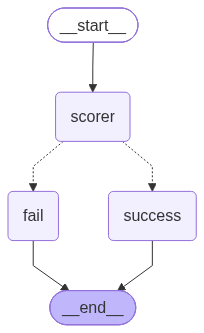

In [2]:
# 5.打印图
from IPython.core.display import Image

display(Image(graph.get_graph(xray=True).draw_mermaid_png()))